# Search: Solving a Maze Using a Goal-based Agent

Student Name: Nguyễn Đăng Khoa - MSSV: 3123410168

I have used the following AI tools: GitHub Copilot, Gemini

I understand that my submission needs to be my own work: NDK


## Learning Outcomes

* Formulate search problems using key components like initial state, actions, and goal state in a deterministic, fully observable environment.
* Implement and compare search algorithms including BFS, DFS, GBFS, A*, and IDS for planning paths through mazes.
* Analyze algorithm performance by measuring path cost, node expansions, depth, and memory usage across various maze types.
* Use visualization tools to represent maze paths and support debugging and analysis.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file. 


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze. 

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent 
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.** 
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state. 
* **Discrete** means that we have a **finite set of states.** The maze has a finite set 
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The 
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible. 

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

In [2]:
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

base_url = "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Search/"
download("maze_helper.py", base_url)

mazes = ["small_maze.txt", "medium_maze.txt", "large_maze.txt", "L_maze.txt", "empty_maze.txt", "empty_maze_2.txt", "loops_maze.txt", "open_maze.txt", ]
for maze in mazes:
    download(maze, base_url)

Here is the small example maze:

In [3]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`. 

In [4]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))

Position(0,0): X
Position(8,1): G


A helper function to visualize the maze is also available.

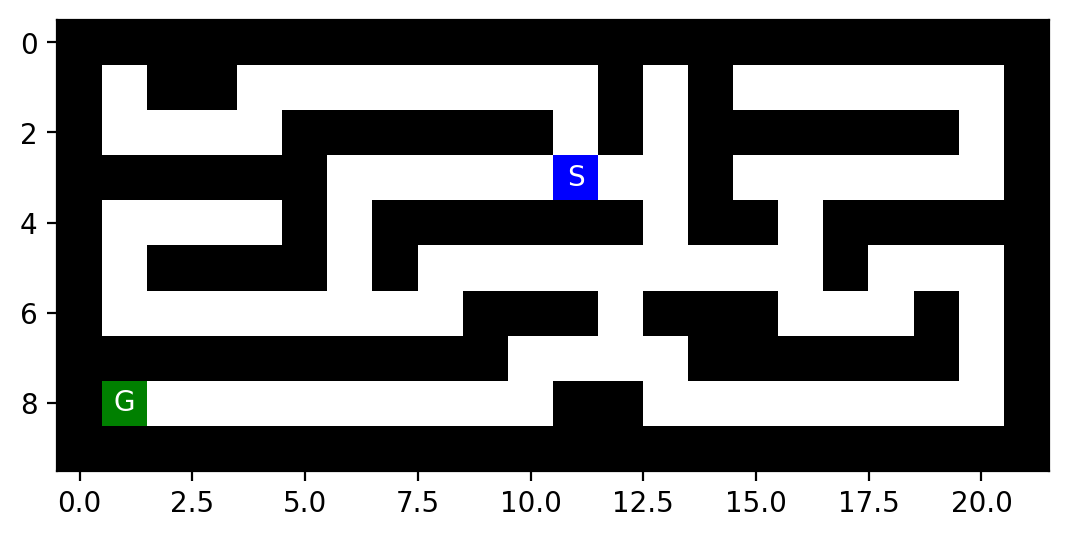

In [5]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [6]:
print("Start location:", mh.find_pos(maze, what = "S"))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [7]:
help(mh)

Help on module maze_helper:

NAME
    maze_helper

DESCRIPTION
    Code for the Maze Assignment
    Usage:
        import maze_helper as mh
        mh.show_some_mazes()

FUNCTIONS
    animate_maze(result, repeat=False)
        (Experimental) Build an animation from a list of mazes.

        Parameters:
            result: a list with the elements path, reached, actions and maze_anim with a list of maze arrays that contain what you want to visualize.
            repeat: if True, the animation will repeat.

    find_pos(maze, what='S')
        Find start/goal in a maze and returns the first one.
        Caution: there is no error checking!

        Parameters:
            maze: a array with characters produced by parse_maze()
            what: the letter to be found ('S' for start and 'G' for goal)

        Returns:
            a tupple (x, y) for the found position.

    look(maze, pos)
        Look at the label of a square with the position as an array of the form (x, y).

        Para

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step. 

In [8]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0
        
        # check if plan is completed
        if self.progress >= len(self.plan):        
            raise Exception("Completed Plan. No more planned actions")
        
        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [9]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['E', 'E', 'N', 'S', 'W', 'N', 'W', 'S', 'N', 'E']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [10]:
my_agent = Planning_Agent(maze, mh.find_pos(maze, what = "S"), mh.find_pos(maze, what = "G"), plan_random)

def environment(agent_function, steps):
    for _ in range(steps):
        try:
            agent_function()
        except Exception as e:
            print(f"Agent exception: {e}")

environment(my_agent.act, steps=11)

Planning...
Following plan... step 0: E
Following plan... step 1: N
Following plan... step 2: W
Following plan... step 3: N
Following plan... step 4: N
Following plan... step 5: S
Following plan... step 6: E
Following plan... step 7: N
Following plan... step 8: N
Following plan... step 9: W
Agent exception: Completed Plan. No more planned actions


Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python. 
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [11]:
class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)    # the state; positions are (row,col)
        self.parent = parent     # reference to parent node. None means root node.
        self.action = action     # action used in the transition function (root node has None)
        self.cost = cost         # for uniform cost this is the depth. It is also g(n) for A* search

    def __str__(self):
        return f"Node - pos = {self.pos}; action = {self.action}; cost = {self.cost}"
    
    def get_path_from_root(self):
        """returns nodes on the path from the root to the current node."""
        node = self
        path = [node]
    
        while not node.parent is None:
            node = node.parent
            path.append(node)
        
        path.reverse()
        
        return(path)

If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithms for solving different mazes:

    - Breadth-first search (BFS)
    - Depth-first search (DFS)
    - Greedy best-first search (GBFS)
    - A* search

2. Run each of the above algorithms on the 
    - [small maze](small_maze.txt), 
    - [medium maze](medium_maze.txt), 
    - [large maze](large_maze.txt), 
    - [open maze](open_maze.txt),
    - [L maze](L_maze.txt),
    - [loops maze](loops_maze.txt),
    - [empty maze](empty_maze.txt), and
    - [empty maze (rotated)](empty_maze_2.txt).
    
3. For each problem instance and each search algorithm, report the following in a table:

    - The solution and its path cost
    - Total number of nodes expanded
    - Maximum tree depth
    - Maximum size of the frontier

4. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General [10 Points]

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [10 Points]

Define the components of the search problem:

* Initial state
* Actions
* Transition model
* Goal state
* Path cost

Use verbal descriptions, variables and equations as appropriate. 

*Note:* You can switch the next block from code to Markdown and use formatting.

# Search-problem definition

The maze is modeled as a deterministic search problem on a 4-connected grid.

- **Initial state:** `S = mh.find_pos(maze, "S")`, the row/column position of the start square.
- **Actions:** `N`, `E`, `S`, `W`, corresponding to moving one square north, east, south, or west.
- **Transition model:** an action moves the agent to the adjacent square if that square is inside the maze and is not a wall (`X`). Illegal moves are not generated.
- **Goal state:** `G = mh.find_pos(maze, "G")`.
- **Path cost:** every legal move has cost 1, so for a path with `k` actions, `g(n) = k`. Therefore minimizing path cost is the same as finding a shortest path in number of moves.

The search algorithms store their search information in `Node` objects, `frontier`, and (where appropriate) `reached`; the maze itself is not used to store search state.

Give some estimates for the problem size:

* $n$: state space size
* $d$: depth of the optimal solution
* $m$: maximum depth of tree
* $b$: maximum branching factor

Describe how you would determine these values for a given maze.

# Problem-size estimates

For a particular maze:

- `n` (state-space size) is the number of traversable cells (`' '`, plus `S` and `G`). It can be counted from the parsed maze.
- `d` is the depth/cost of the shortest solution. We obtain it from a BFS solution because all moves have equal cost.
- `m` is the maximum depth that the search tree can reach. For a finite maze it is bounded by the number of traversable states for a simple path; without cycle checking, a tree can contain repeated states and become arbitrarily deep.
- `b` is the maximum number of legal successors of any state. With four-direction movement, `b <= 4`; walls and borders make the actual value smaller.

The code below computes `n` and the optimal depth for the small maze as an example.

## Task 2: Uninformed search: Breadth-first and depth-first [40 Points]

Implement these search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important notes** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.
* DSF behavior can be implemented using the BFS tree search algorithm and simply changing the order in which the frontier is expanded (this is equivalent to best-first search with path length as the criterion to expand the next node). However, this would be a big mistake since it combines the bad space complexity of BFS with the bad time complexity of DFS! **To take advantage of the significantly smaller memory footprint of DFS, you need to implement DFS in a different way without a `reached` data structure (often also called `visited` or `explored`) and by releasing the memory for nodes that are not needed anymore.**
* Since the proper implementation of DFS does not use a `reached` data structure, redundant path checking abilities are limited to cycle checking. 
You need to implement **cycle checking since DSF is incomplete (produces an infinite loop) if cycles cannot be prevented.** You will see in your experiments that cycle checking in open spaces is challenging.

In [12]:
from collections import deque
import heapq, math, time
import pandas as pd
import matplotlib.pyplot as plt

ACTIONS = [("E", (0, 1)), ("S", (1, 0)), ("W", (0, -1)), ("N", (-1, 0))]
SEARCH_STATS = {}
SEARCH_RESULTS = {}

def legal_successors(maze, pos):
    """Generate legal (action, next_position) pairs without modifying maze."""
    r, c = pos
    out = []
    for action, (dr, dc) in ACTIONS:
        nxt = (r + dr, c + dc)
        if 0 <= nxt[0] < maze.shape[0] and 0 <= nxt[1] < maze.shape[1] and mh.look(maze, nxt) != 'X':
            out.append((action, nxt))
    return out

def actions_from_node(node):
    return [n.action for n in node.get_path_from_root() if n.action is not None]

def positions_from_node(node):
    return [n.pos for n in node.get_path_from_root()]

def _record(name, start_time, solution, expanded, max_depth, max_frontier, memory_peak, reached, explored_order):
    stats = {
        'path_cost': None if solution is None else len(solution),
        'nodes_expanded': expanded,
        'max_tree_depth': max_depth,
        'max_frontier_size': max_frontier,
        'max_nodes_in_memory': memory_peak,
        'time_sec': time.perf_counter() - start_time,
        'reached': set(reached),
        'explored_order': list(explored_order),
    }
    SEARCH_STATS[name] = stats
    return solution

def plan_bfs(maze, start, goal):
    t0=time.perf_counter(); root=Node(start,None,None,0)
    frontier=deque([root]); reached={root.pos}; expanded=0; max_depth=0; max_frontier=1; memory_peak=1; explored=[]
    while frontier:
        node=frontier.popleft(); expanded+=1; explored.append(node.pos); max_depth=max(max_depth,node.cost)
        if node.pos==goal:
            sol=actions_from_node(node); return _record('BFS',t0,sol,expanded,max_depth,max_frontier,max(memory_peak,len(frontier)+1),reached,explored)
        for action,nxt in legal_successors(maze,node.pos):
            if nxt not in reached:
                reached.add(nxt); child=Node(nxt,node,action,node.cost+1); frontier.append(child); max_depth=max(max_depth,child.cost)
        max_frontier=max(max_frontier,len(frontier)); memory_peak=max(memory_peak,len(frontier)+len(reached))
    return _record('BFS',t0,None,expanded,max_depth,max_frontier,memory_peak,reached,explored)

def plan_dfs(maze, start, goal):
    """Depth-first tree search with path-based cycle checking and no global reached set."""
    t0=time.perf_counter(); root=Node(start,None,None,0)
    stack=[root]; expanded=0; max_depth=0; max_frontier=1; memory_peak=1; explored=[]; reached_for_display=set()
    while stack:
        node=stack.pop(); expanded+=1; explored.append(node.pos); reached_for_display.add(node.pos); max_depth=max(max_depth,node.cost)
        if node.pos==goal:
            sol=actions_from_node(node); return _record('DFS',t0,sol,expanded,max_depth,max_frontier,memory_peak,reached_for_display,explored)
        path_positions={n.pos for n in node.get_path_from_root()}
        children=[]
        for action,nxt in legal_successors(maze,node.pos):
            if nxt not in path_positions:
                children.append(Node(nxt,node,action,node.cost+1))
        # Reverse so N,E,S,W is explored in that displayed order with LIFO.
        stack.extend(reversed(children)); max_frontier=max(max_frontier,len(stack)); memory_peak=max(memory_peak,len(stack)+len(node.get_path_from_root()))
    return _record('DFS',t0,None,expanded,max_depth,max_frontier,memory_peak,reached_for_display,explored)

def manhattan(a,b): return abs(a[0]-b[0])+abs(a[1]-b[1])

def _best_first(maze,start,goal,mode):
    t0=time.perf_counter(); root=Node(start,None,None,0); counter=0
    h=lambda p: manhattan(p,goal)
    frontier=[]; heapq.heappush(frontier,((h(start) if mode=='GBFS' else 0),counter,root)); reached={start}; expanded=0; max_depth=0; max_frontier=1; memory_peak=1; explored=[]
    while frontier:
        _,_,node=heapq.heappop(frontier); expanded+=1; explored.append(node.pos); max_depth=max(max_depth,node.cost)
        if node.pos==goal:
            sol=actions_from_node(node); return _record(mode,t0,sol,expanded,max_depth,max_frontier,memory_peak,reached,explored)
        for action,nxt in legal_successors(maze,node.pos):
            if nxt in reached: continue
            reached.add(nxt); child=Node(nxt,node,action,node.cost+1); counter+=1
            priority=h(nxt) if mode=='GBFS' else child.cost+h(nxt)
            heapq.heappush(frontier,(priority,counter,child)); max_depth=max(max_depth,child.cost)
        max_frontier=max(max_frontier,len(frontier)); memory_peak=max(memory_peak,len(frontier)+len(reached))
    return _record(mode,t0,None,expanded,max_depth,max_frontier,memory_peak,reached,explored)

def plan_gbfs(maze,start,goal): return _best_first(maze,start,goal,'GBFS')
def plan_astar(maze,start,goal): return _best_first(maze,start,goal,'A*')

def load_maze(filename):
    with open(filename) as f: return mh.parse_maze(f.read())

def run_algorithm(filename, algorithm):
    maze=load_maze(filename); start=mh.find_pos(maze,'S'); goal=mh.find_pos(maze,'G')
    fn={'BFS':plan_bfs,'DFS':plan_dfs,'GBFS':plan_gbfs,'A*':plan_astar}[algorithm]
    path=fn(maze,start,goal); SEARCH_RESULTS[(filename,algorithm)] = (path,SEARCH_STATS[algorithm])
    return path

def show_search_result(filename, algorithm):
    maze=load_maze(filename); path=run_algorithm(filename,algorithm); stats=SEARCH_STATS[algorithm]
    display_maze=np.copy(maze)
    for pos in stats['reached']:
        if display_maze[pos]==' ': display_maze[pos]='.'
    if path is not None:
        pos=mh.find_pos(maze,'S'); display_maze[pos]='S'
        for action in path:
            dr,dc=dict(ACTIONS)[action]; pos=(pos[0]+dr,pos[1]+dc)
            if display_maze[pos] not in ('S','G'): display_maze[pos]='P'
    mh.show_maze(display_maze)
    print(f"{filename} | {algorithm}: path cost={stats['path_cost']}, expanded={stats['nodes_expanded']}, max depth={stats['max_tree_depth']}, max frontier={stats['max_frontier_size']}")

# Problem-size example for the small maze.
small = load_maze('small_maze.txt')
traversable = np.logical_or(small != 'X', small == 'S')
print('small maze state-space estimate n =', int(np.sum(traversable)))
run_algorithm('small_maze.txt','BFS')
print('small maze optimal depth d =', SEARCH_STATS['BFS']['path_cost'])

small maze state-space estimate n = 94
small maze optimal depth d = 19


How does BFS and DFS (without a reached data structure) deal with loops (cycles)?

### Discussion: cycles

- **BFS:** uses a global `reached` set. Once a state is reached, it is not inserted again, so cycles do not cause repeated expansion of the same state.
- **DFS:** deliberately does **not** use a global `reached` set because that would destroy the intended low-memory DFS implementation. Instead, it performs **path-based cycle checking**: a successor is rejected when its state already occurs on the current root-to-node path. This prevents an immediate loop such as `A -> B -> A`, while still allowing the same state to be reached by a different branch.

Are your implementations complete and optimal? Explain why. What is the time and space complexity of each of **your** implementations? Especially discuss the difference in space complexity between BFS and DFS.

### Completeness, optimality, and complexity

With unit step costs and a finite state space, BFS with global reached checking is complete and optimal. Its worst-case time and space are `O(b^d)` (more generally `O(b^(d+1))` depending on the counting convention).

The DFS implementation is complete on these finite mazes because path-based cycle checking prevents infinite cycles, but DFS is **not optimal**: it can find a much longer solution before a shorter one. Its worst-case time is `O(b^m)` and its active search memory is `O(bm)` because it keeps a depth-first stack plus the current paths rather than a global reached set.

Thus the key practical difference is memory: BFS stores a large frontier/reached structure, while DFS trades optimality for a much smaller active memory footprint.

## Task 3: Informed search: Implement greedy best-first search and A* search  [20 Points]

You can use the map to estimate the distance from your current position to the goal using the Manhattan distance (see https://en.wikipedia.org/wiki/Taxicab_geometry) as a heuristic function. Both algorithms are based on Best-First search which requires only a small change from the BFS algorithm you have already implemented (see textbook/slides). 

In [13]:
# Informed search: GBFS and A*

def _check_searches():
    for fn in ['small_maze.txt','medium_maze.txt','large_maze.txt','open_maze.txt']:
        for alg in ['GBFS','A*']:
            run_algorithm(fn,alg)
            s=SEARCH_STATS[alg]
            print(fn, alg, 'cost=',s['path_cost'], 'expanded=',s['nodes_expanded'], 'max_frontier=',s['max_frontier_size'])

_check_searches()

small_maze.txt GBFS cost= 29 expanded= 40 max_frontier= 5
small_maze.txt A* cost= 19 expanded= 53 max_frontier= 8
medium_maze.txt GBFS cost= 74 expanded= 79 max_frontier= 4
medium_maze.txt A* cost= 68 expanded= 222 max_frontier= 8
large_maze.txt GBFS cost= 210 expanded= 468 max_frontier= 20
large_maze.txt A* cost= 210 expanded= 550 max_frontier= 12
open_maze.txt GBFS cost= 68 expanded= 90 max_frontier= 66
open_maze.txt A* cost= 54 expanded= 536 max_frontier= 25


Are your implementations complete and optimal? What is the time and space complexity?

### Completeness, optimality, and complexity

GBFS prioritizes the smallest heuristic `h(n)`, so it is strongly goal-directed but does not guarantee a shortest path. A* prioritizes `f(n)=g(n)+h(n)`. With unit-cost 4-direction movement, Manhattan distance is admissible (and consistent), so A* with this heuristic is complete and optimal for these mazes when the reached/best-cost handling is used as implemented.

For both informed searches, worst-case time and space are exponential in the search depth. In practice, a useful heuristic can reduce the number of expanded states substantially compared with uninformed BFS.

## Task 4: Comparison and discussion [20 Points] 

Run experiments to compare the implemented algorithms.

How to deal with issues:

* Your implementation returns unexpected results: Try to debug and fix the code. Visualizing the maze, the current path and the frontier after every step is very helpful. If the code still does not work, then mark the result with an asterisk (*) and describe the issue below the table.

* Your implementation cannot consistently solve a specific maze and ends up in an infinite loop:
    Debug (likely your frontier and cycle checking for DFS are the issue). If it is a shortcoming of the algorithm/implementation, then put "N/A*" in the results table and describe why this is happening.

,maze,algorithm,path_cost,nodes_expanded,max_depth,max_memory_nodes,max_frontier,time_sec
0,small,BFS,19,93,20,96,9,0.000367
1,small,DFS,37,38,37,44,7,0.000266
2,small,GBFS,29,40,29,49,5,0.000185
3,small,A*,19,53,19,66,8,0.000234
4,medium,BFS,68,269,68,274,9,0.000953
5,medium,DFS,74,75,74,82,8,0.000752
6,medium,GBFS,74,79,74,86,4,0.000389
7,medium,A*,68,222,68,235,8,0.000966
8,large,BFS,210,621,211,630,8,0.002296
9,large,DFS,210,418,222,257,35,0.008466


Visualization: small_maze.txt with BFS


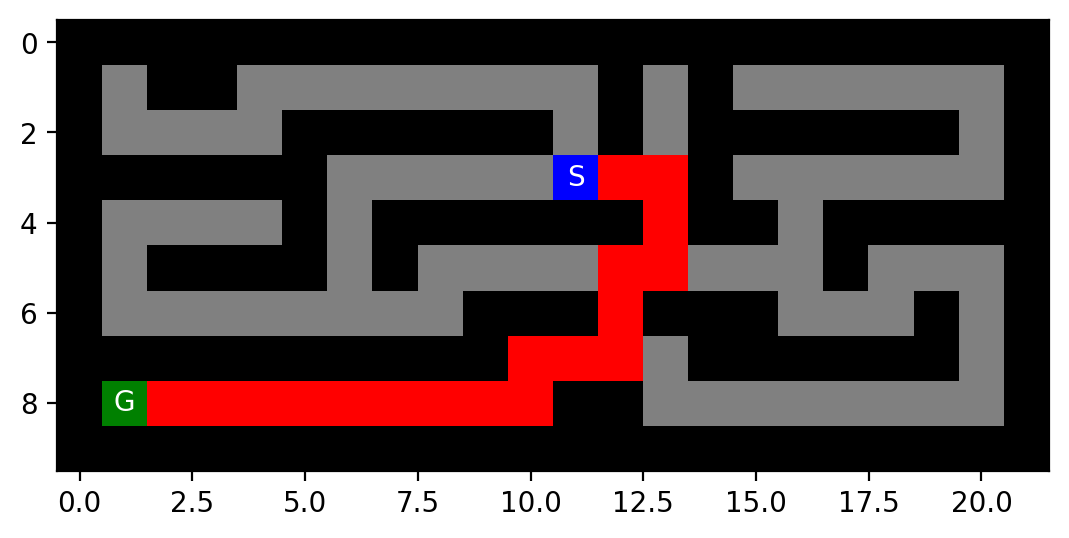

small_maze.txt | BFS: path cost=19, expanded=93, max depth=20, max frontier=9
Visualization: medium_maze.txt with A*


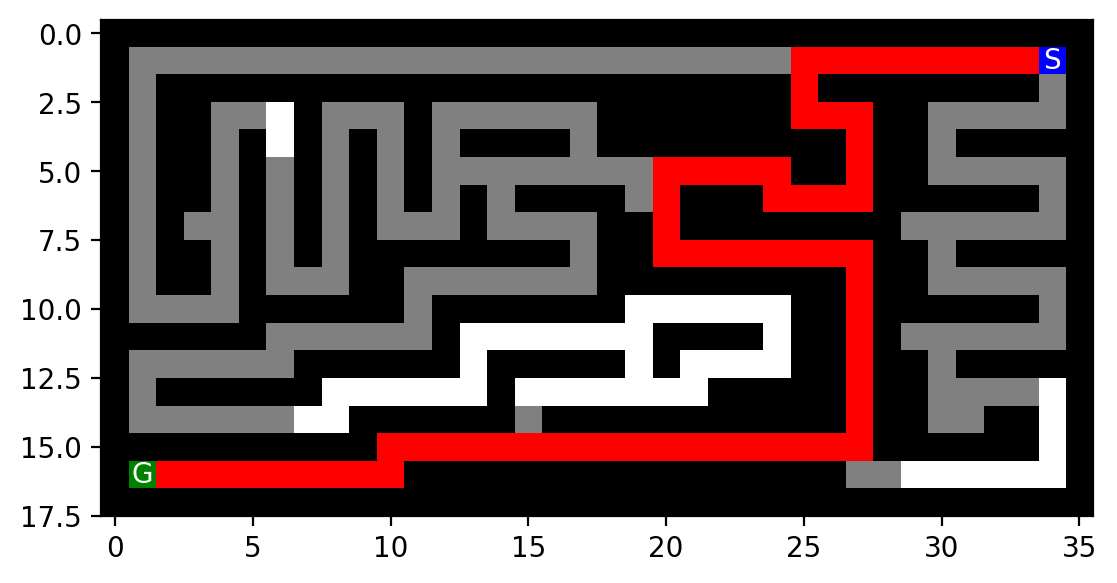

medium_maze.txt | A*: path cost=68, expanded=222, max depth=68, max frontier=8
Visualization: open_maze.txt with DFS


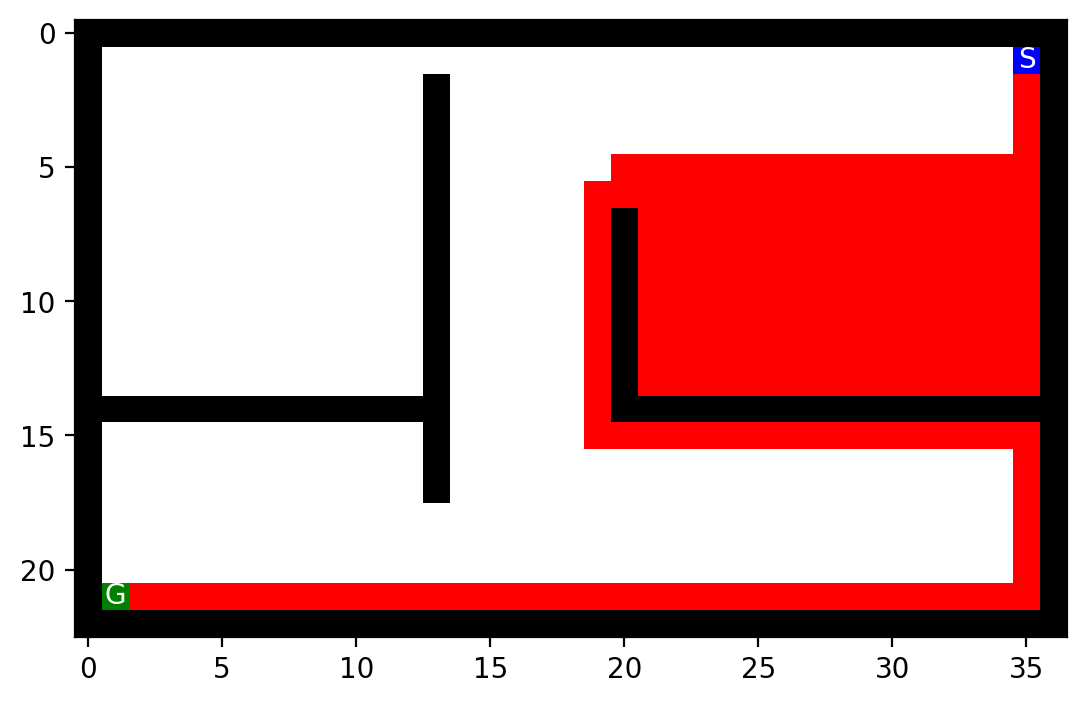

open_maze.txt | DFS: path cost=206, expanded=207, max depth=206, max frontier=199


In [14]:
# Run the required comparison experiments.
maze_files = ['small_maze.txt','medium_maze.txt','large_maze.txt','open_maze.txt','L_maze.txt','loops_maze.txt','empty_maze.txt','empty_maze_2.txt']
algorithms = ['BFS','DFS','GBFS','A*']
rows=[]
for mf in maze_files:
    for alg in algorithms:
        try:
            path=run_algorithm(mf,alg); s=SEARCH_STATS[alg]
            rows.append({'maze':mf.replace('_maze.txt',''),'algorithm':alg,'path_cost':s['path_cost'],'nodes_expanded':s['nodes_expanded'],'max_depth':s['max_tree_depth'],'max_memory_nodes':s['max_nodes_in_memory'],'max_frontier':s['max_frontier_size'],'time_sec':s['time_sec']})
        except Exception as e:
            rows.append({'maze':mf.replace('_maze.txt',''),'algorithm':alg,'path_cost':'ERROR','nodes_expanded':'ERROR','max_depth':'ERROR','max_memory_nodes':'ERROR','max_frontier':'ERROR','time_sec':None})
comparison_df = pd.DataFrame(rows)
display(comparison_df)

# Show representative visualizations required by the assignment.
for mf,alg in [('small_maze.txt','BFS'),('medium_maze.txt','A*'),('open_maze.txt','DFS')]:
    print(f'Visualization: {mf} with {alg}')
    show_search_result(mf,alg)

Complete the following table for each maze.

__Small maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size |
|-----------|-----------|---------------------|----------------|--------------------------|-------------------|
| BFS       | 19        | 93                  | 20             | 96                       | 9                 |
| DFS       | 37        | 38                  | 37             | 44                       | 7                 |
| GBS       | 29        | 40                  | 29             | 49                       | 5                 |
| A*        | 19        | 53                  | 19             | 66                       | 8                 |

__Medium maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size |
|-----------|-----------|---------------------|----------------|--------------------------|-------------------|
| BFS       | 68        | 269                 | 68             | 274                      | 9                 |
| DFS       | 74        | 75                  | 74             | 82                       | 8                 |
| GBS       | 74        | 79                  | 74             | 86                       | 4                 |
| A*        | 68        | 222                 | 68             | 235                      | 8                 |

__Large maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size |
|-----------|-----------|---------------------|----------------|--------------------------|-------------------|
| BFS       | 210       | 621                 | 211            | 630                      | 8                 |
| DFS       | 210       | 418                 | 222            | 257                      | 35                |
| GBS       | 210       | 468                 | 210            | 507                      | 20                |
| A*        | 210       | 550                 | 210            | 565                      | 12                |

__Open maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size |
|-----------|-----------|---------------------|----------------|--------------------------|-------------------|
| BFS       | 54        | 683                 | 54             | 687                      | 25                |
| DFS       | 206       | 207                 | 206            | 405                      | 199               |
| GBS       | 68        | 90                  | 68             | 221                      | 66                |
| A*        | 54        | 536                 | 54             | 576                      | 25                |


Present the results as using charts (see [Python Code Examples/charts and tables](../HOWTOs/charts_and_tables.ipynb)). 

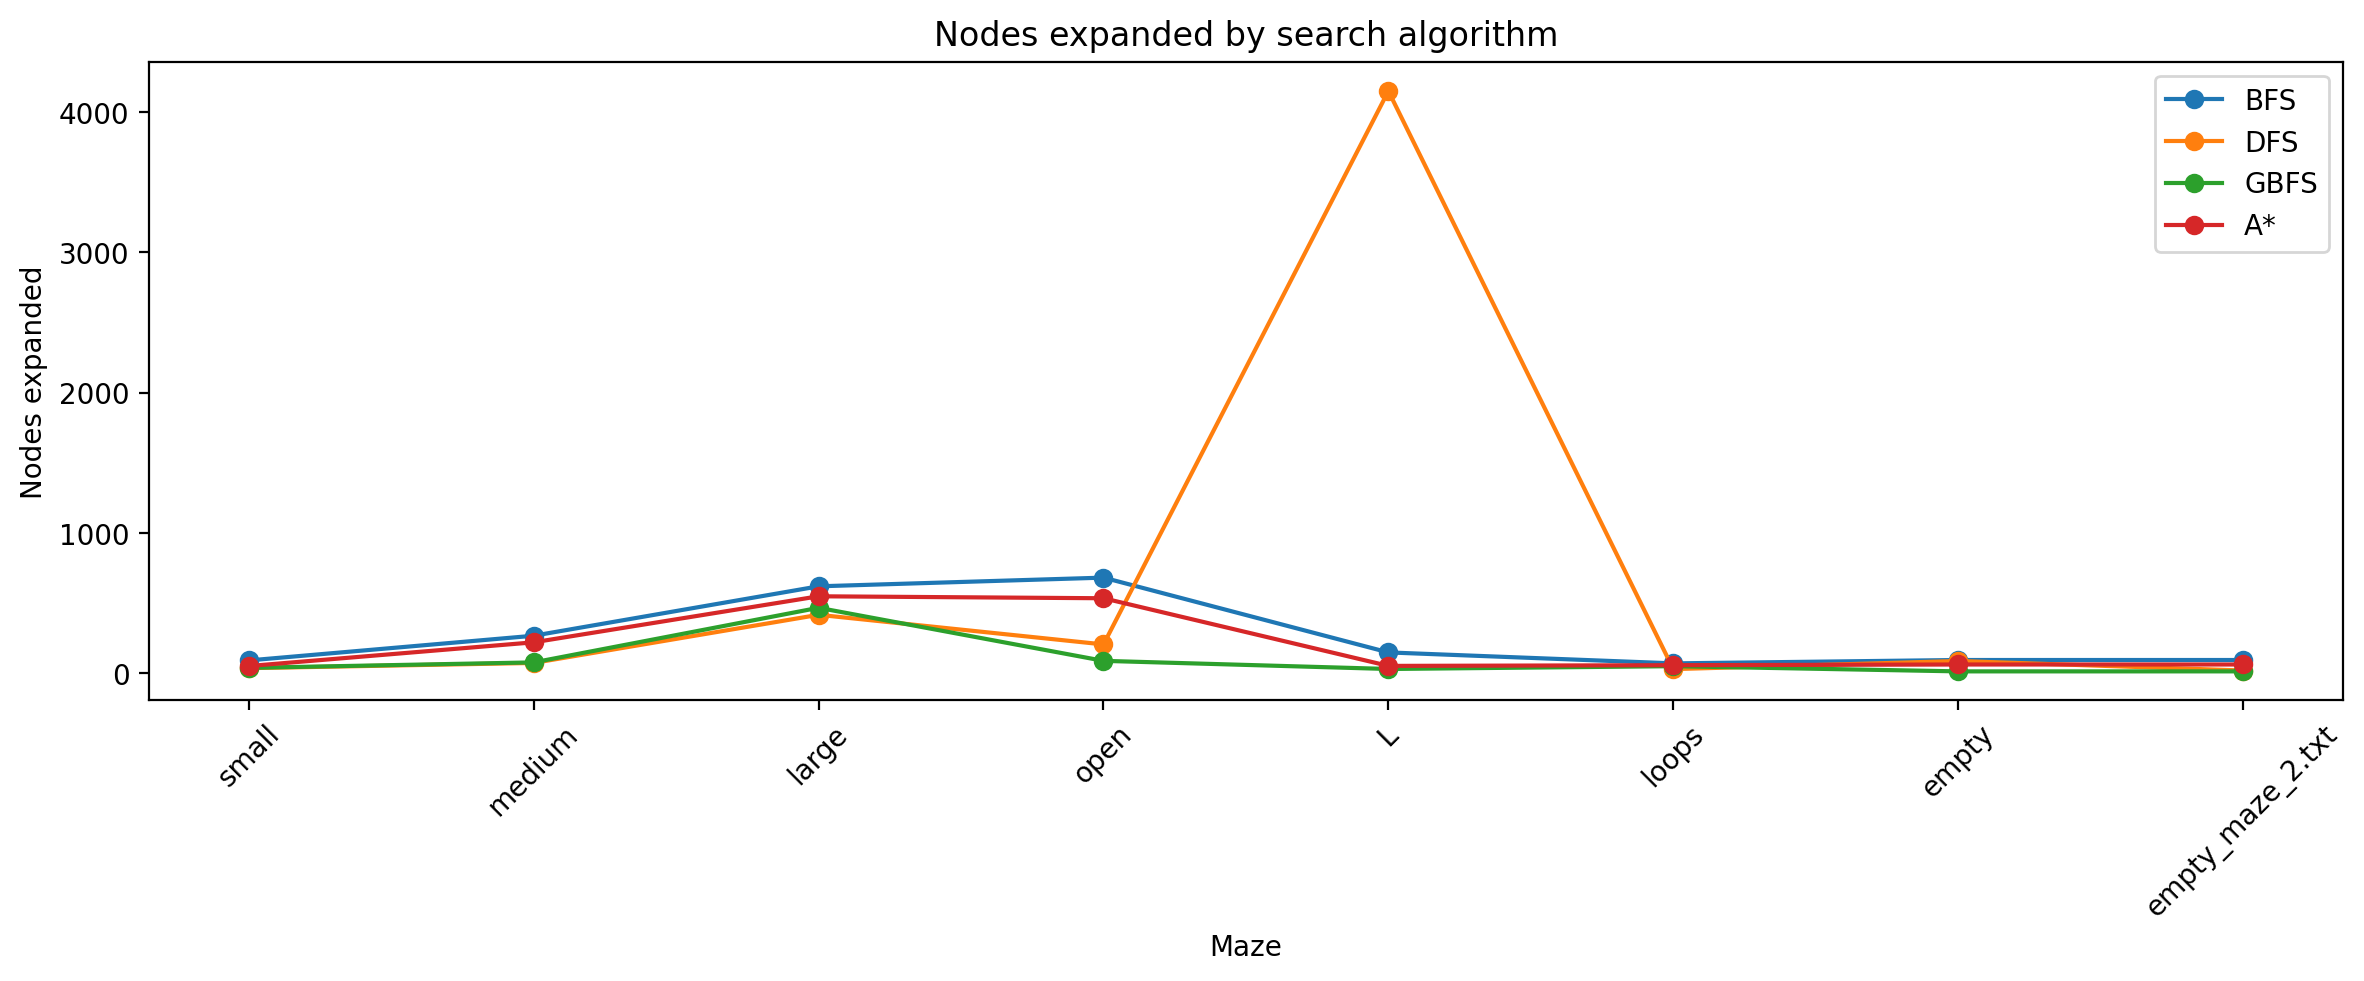

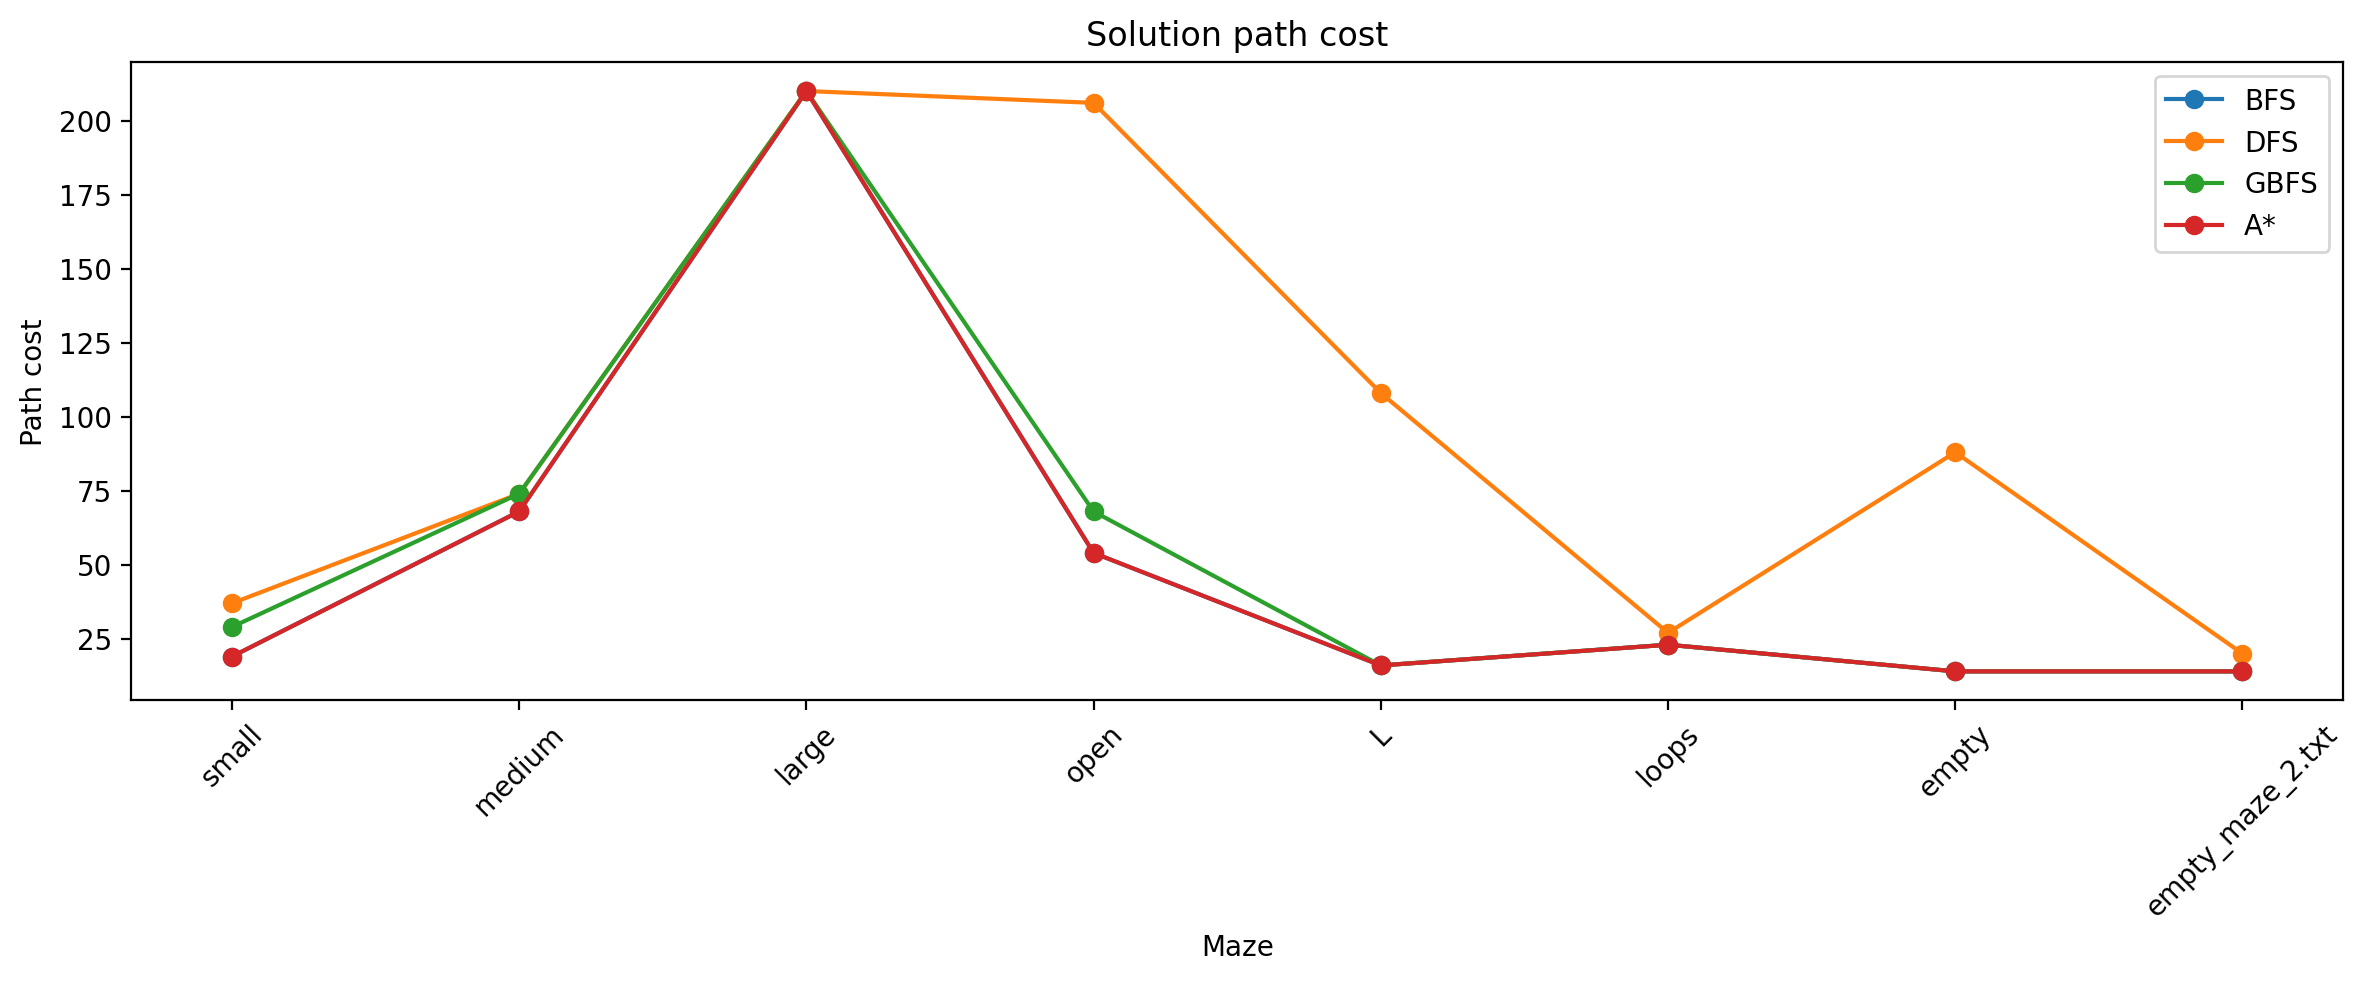

In [15]:
# Charts for the comparison.
plot_df = comparison_df.copy()
fig, ax = plt.subplots(figsize=(12,5))
for alg in algorithms:
    sub=plot_df[plot_df.algorithm==alg]
    ax.plot(sub.maze, sub.nodes_expanded, marker='o', label=alg)
ax.set_title('Nodes expanded by search algorithm')
ax.set_xlabel('Maze'); ax.set_ylabel('Nodes expanded'); ax.legend(); ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12,5))
for alg in algorithms:
    sub=plot_df[plot_df.algorithm==alg]
    ax.plot(sub.maze, sub.path_cost, marker='o', label=alg)
ax.set_title('Solution path cost')
ax.set_xlabel('Maze'); ax.set_ylabel('Path cost'); ax.legend(); ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

Discuss the most important lessons you have learned from implementing the different search strategies. 

### Main lessons

1. **BFS** is dependable for these unit-cost mazes and returns shortest paths, but its frontier and reached set can consume substantial memory.
2. **DFS** uses much less active memory and can quickly find a solution, but the solution may be much longer than the optimum and its behavior is sensitive to successor order.
3. **GBFS** uses the Manhattan heuristic to head toward the goal. It can expand fewer nodes than BFS, but greediness does not guarantee optimal paths.
4. **A*** combines accumulated path cost `g(n)` with heuristic estimate `h(n)`. With the Manhattan heuristic for four-direction movement, it retains optimality while often expanding fewer states than BFS.
5. **Cycle checking** is essential for DFS. Path-based checking prevents infinite loops without introducing the full memory cost of a global reached set.
6. The experiments illustrate the central search trade-off: stronger guidance can reduce work, while stronger duplicate detection can increase memory use.

## Advanced task: IDS and Multiple goals

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### IDS 
Implement IDS (iterative deepening search) using your DFS implementation. Test IDS on the mazes above. You may run into some issues with mazes with open spaces. If you cannot resolve the issues, then report and discuss what causes the problems.

In [16]:
# Bonus: Iterative Deepening Search (IDS)
def depth_limited(maze,start,goal,limit):
    root=Node(start,None,None,0); expanded=0; reached=set(); max_frontier=1; max_depth=0
    def rec(node,path_states):
        nonlocal expanded,max_frontier,max_depth
        expanded+=1; reached.add(node.pos); max_depth=max(max_depth,node.cost)
        if node.pos==goal: return node
        if node.cost>=limit: return None
        for action,nxt in legal_successors(maze,node.pos):
            if nxt in path_states: continue
            child=Node(nxt,node,action,node.cost+1)
            ans=rec(child,path_states|{nxt})
            if ans is not None: return ans
        return None
    ans=rec(root,{root.pos})
    return ans,expanded,reached,max_depth

def plan_ids(maze,start,goal):
    t0=time.perf_counter(); total_expanded=0; reached=set(); max_depth=0
    # In a finite grid, a simple path cannot need more than the number of traversable states - 1 moves.
    max_limit=int(np.sum(maze!='X'))
    for limit in range(max_limit+1):
        ans,expanded,rch,depth=depth_limited(maze,start,goal,limit)
        total_expanded+=expanded; reached |= rch; max_depth=max(max_depth,depth)
        if ans is not None:
            sol=actions_from_node(ans)
            SEARCH_STATS['IDS']={'path_cost':len(sol),'nodes_expanded':total_expanded,'max_tree_depth':max_depth,'max_frontier_size':limit+1,'max_nodes_in_memory':limit+1,'time_sec':time.perf_counter()-t0,'reached':reached,'explored_order':list(reached)}
            return sol
    return None

for mf in ['small_maze.txt','medium_maze.txt']:
    maze=load_maze(mf); path=plan_ids(maze,mh.find_pos(maze,'S'),mh.find_pos(maze,'G'))
    print(mf,'IDS path cost=',None if path is None else len(path),'expanded=',SEARCH_STATS['IDS']['nodes_expanded'])

small_maze.txt IDS path cost= 19 expanded= 1036
medium_maze.txt IDS path cost= 68 expanded= 16212


### Multiple Goals 
Create a few mazes with multiple goals by adding one or two more goals to the medium size maze. The agent is done when it finds one of the goals.
Solve the maze with your implementations for DFS, BFS, and IDS. Run experiments to show which implementations find the optimal solution and which do not. Discuss why that is the case.

In [17]:
# Bonus: multiple goals

def plan_bfs_multiple_goals(maze,start,goals):
    goals=set(goals); root=Node(start,None,None,0); q=deque([root]); reached={start}
    while q:
        node=q.popleft()
        if node.pos in goals: return actions_from_node(node), node.pos
        for action,nxt in legal_successors(maze,node.pos):
            if nxt not in reached:
                reached.add(nxt); q.append(Node(nxt,node,action,node.cost+1))
    return None,None

# Example: use the original medium maze and add a second goal on an open square.
medium=load_maze('medium_maze.txt')
start=mh.find_pos(medium,'S'); original_goal=mh.find_pos(medium,'G')
open_cells=list(zip(*np.where(medium==' ')))
extra_goal=next(p for p in reversed(open_cells) if p not in {start,original_goal})
medium_multi=np.copy(medium); medium_multi[original_goal]='G'; medium_multi[extra_goal]='G'
path,found_goal=plan_bfs_multiple_goals(medium_multi,start,[original_goal,extra_goal])
print('Multiple-goal BFS found:',found_goal,'path cost:',None if path is None else len(path))

Multiple-goal BFS found: (np.int64(16), np.int64(34)) path cost: 39


## More Advanced Problems to Think About (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Intersection as States
Instead of defining each square as a state, use only intersections as states. Now the storage requirement is reduced, but the path length between two intersections can be different. If we use total path length measured as the number of squares as path cost, how can we make sure that BFS and iterative deepening search is optimal? Change the code to do so.

In [18]:
# Not required for credit; left intentionally as an extension prompt.

### Weighted A* search
Modify your A* search to add weights (see text book) and explore how different weights influence the result.

In [19]:
# Extension: Weighted A*
def plan_weighted_astar(maze,start,goal,w=1.5):
    t0=time.perf_counter(); root=Node(start,None,None,0); counter=0; frontier=[(w*manhattan(start,goal),counter,root)]; reached={start}; expanded=0
    while frontier:
        _,_,node=heapq.heappop(frontier); expanded+=1
        if node.pos==goal:
            sol=actions_from_node(node)
            SEARCH_STATS[f'Weighted A* ({w})']={'path_cost':len(sol),'nodes_expanded':expanded,'max_tree_depth':node.cost,'max_frontier_size':len(frontier),'max_nodes_in_memory':len(frontier)+len(reached),'time_sec':time.perf_counter()-t0,'reached':reached,'explored_order':[]}
            return sol
        for action,nxt in legal_successors(maze,node.pos):
            if nxt in reached: continue
            reached.add(nxt); counter+=1; child=Node(nxt,node,action,node.cost+1)
            heapq.heappush(frontier,(child.cost+w*manhattan(nxt,goal),counter,child))
    return None

maze=load_maze('small_maze.txt'); start=mh.find_pos(maze,'S'); goal=mh.find_pos(maze,'G')
for w in [1.0,1.5,2.0]:
    p=plan_weighted_astar(maze,start,goal,w); print('w=',w,'path cost=',None if p is None else len(p),'expanded=',SEARCH_STATS[f'Weighted A* ({w})']['nodes_expanded'])

w= 1.0 path cost= 19 expanded= 53
w= 1.5 path cost= 19 expanded= 41
w= 2.0 path cost= 19 expanded= 43


### Unknown Maze
What happens if the agent does not know the layout of the maze in advance? This means that the agent faces an unknown environment, where it does not know the transition function. How does the environment look then (PEAS description)? How would you implement a rational agent to solve the maze? What if the agent still has a GPS device to tell the distance to the goal?

### Unknown maze: PEAS and a rational agent

If the maze layout is unknown, the agent no longer has the complete transition model in advance. A suitable PEAS description is:

- **Performance:** reach the goal, preferably with a short path and few actions/time steps.
- **Environment:** an initially unknown grid maze containing walls, free cells, a start, and a goal.
- **Actuators:** move north, east, south, or west.
- **Sensors:** observe the current location and nearby/visible obstacles and the goal information available to the agent.

A rational agent can maintain an internal map of discovered cells, update it after each observation, and repeatedly plan a path through the currently known free space. If the agent also has GPS/distance-to-goal information, that measurement can provide an additional heuristic for choosing which frontier states to explore.